# 08 - Signatures comme regresseurs lineaires (Linear BCS / Linear REG)

Couverture lineaire d'un payoff **polynomial** sous **Black-Scholes (GBM)** via les
signatures du chemin **lead-lag**, d'apres Abi Jaber & Gerard (Sec. 5.1, Tableau 5).

Deux methodes :
- **Linear BCS** -- regression des moindres carres du P&L empirique trajectoire par
  trajectoire (eq. apprentissage direct).
- **Linear REG** -- n'utilise que la **signature esperee** `E[S^LL]` (eq. 3.8-3.9) :
  linearisation du payoff (`xi`), forme quadratique shuffle `J(theta)=theta^T Q theta - 2 b^T theta`.

Le minimum global de Linear REG coincide avec Linear BCS ; l'ecart du papier vient
de leur optimiseur (descente de gradient multi-start) qui n'atteint pas exactement
ce minimum. Ce notebook ne fait qu'**importer et appeler** le package `linear_hedging`.


In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np

from models import simulate_gbm, compute_payoff_polynomial
from linear_hedging import (
    bs_price, bs_pnl, pnl_stats,
    build_path_LL, signature_transform,
    hedging_word_indices, linear_bcs,
    build_xi, hedging_words, expected_signature,
    build_reg_system, solve_reg, linear_reg_gradient_descent, reg_pnl,
)
from utils.plotting import plot_pnl_distribution


## 1. Parametres et simulation (papier, Sec. 5.1)

GBM `S0=1, sigma=0.25, T=0.5, J=126`. Payoff polynomial
`xi = sum_k c_k S_T^k` avec `c = (-1/16, 1/2, -7/8, 1/2, -1/16)`.
Jeux d'entrainement (`I=10000`, `seed=42`) et de test hors-echantillon
(`I=20000`, `seed=123`).


In [2]:
S0, SIGMA, T, J = 1.0, 0.25, 0.5, 126
I_train, I_test = 10_000, 20_000
COEF = np.array([-1/16, 1/2, -7/8, 1/2, -1/16])   # c_0..c_4

S_train = simulate_gbm(S0, SIGMA, T, J, I_train, seed=42)
S_test  = simulate_gbm(S0, SIGMA, T, J, I_test,  seed=123)

print("E[S_T]      =", S_train[:, -1].mean(),        " (cible 1.0)")
print("Var[log S_T]=", np.log(S_train[:, -1]).var(), " (cible 0.03125)")

xi_train = compute_payoff_polynomial(S_train, COEF)
xi_test  = compute_payoff_polynomial(S_test,  COEF)


E[S_T]      = 1.0011652386708256  (cible 1.0)
Var[log S_T]= 0.030146134265771552  (cible 0.03125)


## 2. Benchmark Black-Scholes (delta en forme close)

`V_t = sum_k c_k S_t^k exp(1/2 k(k-1) sigma^2 (T-t))` et son delta analytique.
P&L de couverture auto-financee discrete.


In [3]:
print("V0 (Black-Scholes a t=0) =", bs_price(0.0, S0, COEF, SIGMA, T))

pnl_bs = bs_pnl(S_test, COEF, SIGMA, T, S0)
mse_bs, mean_bs = pnl_stats(pnl_bs)
print(f"BS  out-of-sample MSE  = {mse_bs:.4e}   (cible papier 1.78e-6)")
print(f"BS  out-of-sample mean = {mean_bs:.4e}  (cible papier 9.73e-6)")


V0 (Black-Scholes a t=0) = 0.008477698003386644
BS  out-of-sample MSE  = 1.8120e-06   (cible papier 1.78e-6)
BS  out-of-sample mean = 1.1465e-05  (cible papier 9.73e-6)


## 3. Signatures lead-lag

Chemin a 3 canaux `X = (tau, S_lag, S_lead)` (transformee de Hoff) puis signature
tronquee a l'ordre 4. Un seul canal de temps `tau = t^lag` suffit : les mots de
hedge vivent dans `{tau, S_lag}^* . S_lead`, le canal `t^lead` est inerte.


In [4]:
DEPTH = 4
sig_train = signature_transform(build_path_LL(S_train, T), DEPTH)
sig_test  = signature_transform(build_path_LL(S_test,  T), DEPTH)
print("forme signature train :", sig_train.shape)   # (I, 120) pour 3 canaux, ordre 4


forme signature train : (10000, 120)


## 4. Linear BCS (regression empirique du P&L)

Features = `[1 | colonnes des mots de hedging v.S_lead]`, regression des moindres
carres sur le payoff. `theta[0]` est la richesse initiale apprise `X0`.


In [5]:
valid_idx = hedging_word_indices(DEPTH)
theta_bcs, pnl_bcs = linear_bcs(sig_train, sig_test, valid_idx, xi_train, xi_test)

mse_bcs, mean_bcs = pnl_stats(pnl_bcs)
print(f"nb mots de hedging = {len(valid_idx)}")
print(f"X0 (appris)        = {theta_bcs[0]:.6f}   (prix BS ~0.008478)")
print(f"BCS out-of-sample MSE  = {mse_bcs:.4e}   (cible papier 1.81e-6)")
print(f"BCS out-of-sample mean = {mean_bcs:.4e}  (cible papier -1.63e-5)")


nb mots de hedging = 15
X0 (appris)        = 0.008484   (prix BS ~0.008478)
BCS out-of-sample MSE  = 1.8195e-06   (cible papier 1.81e-6)
BCS out-of-sample mean = 1.8538e-05  (cible papier -1.63e-5)


## 5. Linear REG (signature esperee, eq. 3.8-3.9)

1. **Payoff linearise** `xi` : formule fermee sur les mots prix-lag `(2,)^m`.
2. **E[S^LL]** : moyenne empirique des signatures lead-lag a l'ordre `2M`.
3. **Forme quadratique shuffle** `J(theta) = theta^T Q theta - 2 b^T theta`, avec
   base de hedging `HW = {1,2}^* . (lettre prix-lead)`.

On compare la **solution fermee** `theta = Q^{-1} b` (= minimum global = BCS) a la
**descente de gradient multi-start** fidele a l'optimiseur du papier.


In [6]:
M = DEPTH
xi    = build_xi(COEF, S0)             # payoff linearise (dict)
HW    = hedging_words(M)               # mot vide + mots de hedging  (16 mots)
E_sig = expected_signature(S_train, T, 2 * M)   # ordre 8 (~quelques s)

Q, b = build_reg_system(E_sig, HW, xi)
print("nb mots HW =", len(HW), "| E_sig[()] =", E_sig[()])

# solution fermee (minimum global)
theta_exact = solve_reg(Q, b)
pnl_reg_exact = reg_pnl(theta_exact, S_test, HW, T, M, xi_test)
mse_ex, mean_ex = pnl_stats(pnl_reg_exact)
print(f"REG exact  X0={theta_exact[0]:.6f}  MSE={mse_ex:.4e}  (= BCS)")

# descente de gradient multi-start (methode du papier)
theta_gd, J_gd = linear_reg_gradient_descent(Q, b, n_restarts=10, steps=4000, lr=1e-2, seed=0)
pnl_reg_gd = reg_pnl(theta_gd, S_test, HW, T, M, xi_test)
mse_gd, mean_gd = pnl_stats(pnl_reg_gd)
print(f"REG GD     X0={theta_gd[0]:.6f}  MSE={mse_gd:.4e}  (cible papier 2.19e-6)")
print(f"max |theta_gd - theta_exact| = {np.abs(theta_gd - theta_exact).max():.3e}")


nb mots HW = 16 | E_sig[()] = 1.0
REG exact  X0=0.008484  MSE=1.8195e-06  (= BCS)
REG GD     X0=0.008484  MSE=1.8214e-06  (cible papier 2.19e-6)
max |theta_gd - theta_exact| = 2.541e-01


## 6. Densites de P&L hors-echantillon

Superposition des trois strategies : Black-Scholes (reference), Linear BCS,
Linear REG (solution fermee). Les distributions doivent etre quasi confondues.


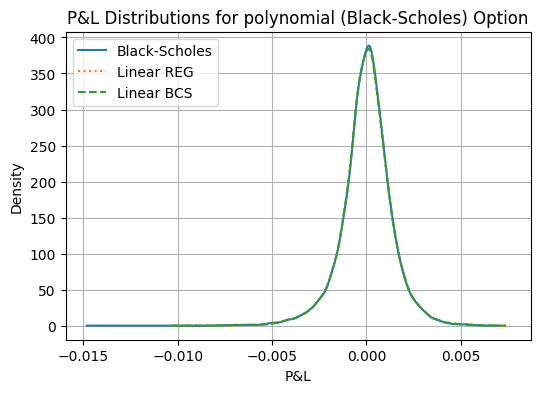

In [7]:
series = [
    (pnl_bs,        'Black-Scholes',  'tab:blue',   '-'),
    (pnl_reg_exact, 'Linear REG',     'tab:orange', ':'),
    (pnl_bcs,       'Linear BCS',     'tab:green',  '--'),
]
plot_pnl_distribution(series, title='polynomial (Black-Scholes)')
